## Импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score


## Загрузка и подготовка данных

Загружен датасет с медицинскими расходами. Категориальные признаки (sex, smoker, region) закодированы с помощью get_dummies. Целевая переменная charges отделена от матрицы признаков.

Данные разделены на обучающую и тестовую выборки. Признаки стандартизированы.


In [8]:
df = pd.read_csv("Medical Cost Personal Datasets.csv")

# Превращаем текстовые категории в числовые (sex, smoker, region)
df = pd.get_dummies(df, drop_first=True)

# Целевая переменная - это charges 
X = df.drop("charges", axis=1)
y = df["charges"]

# Разделение на обучающую и тестовую выборки 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабирование признаков 
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) 
X_test = scaler.transform(X_test)

print(X_train.shape)

(1070, 8)


Вывод: данные подготовлены к обучению, тестовая выборка отложена для оценки качества.

## Бинарная классификация

По тренировочной выборке рассчитана медиана расходов (значения выше медианы получили метку 1, значения ниже получили метку 0)

Обучена логистическая регрессия. Модель выдаёт вероятность принадлежности к классу 1, после чего вероятность переводится в класс по порогу 0.5. Выведены предсказания для первых пяти объектов и рассчитана доля верных ответов.

In [9]:
# Определяем медиану расходов по тренировочной выборке
median_price = y_train.median()

# Создаем бинарные метки классов
y_train_class = (y_train > median_price).astype(int)
y_test_class = (y_test > median_price).astype(int)

# Обучаем логистическую регрессию
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

display(
    pd.DataFrame(
        {
            "Вероятность (Сигмоида)": sample_probs,
            "Класс (Порог 0.5)": sample_preds,
            "Факт": y_test_class.iloc[:5].values
        }
    ).round(3)
)

print(f"Точность классификации (Accuracy): {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.558,1,0
1,0.190,0,0
2,1.000,1,1
3,0.485,0,0
4,0.978,1,1


Точность классификации (Accuracy): 0.9104


Вывод: точность классификации составила около 0.91, что говорит о хорошей разделимости классов по выбранным признакам.

## Регрессия: МНК и SGD

Выполнено сравнение двух моделей регрессии. Первая модель - аналитический МНК (LinearRegression), который вычисляет решение через матричные операции. Вторая - SGDRegressor, подбирающий веса итеративно.

Для каждой модели замерено время обучения и рассчитаны метрики RMSE и R2. RMSE отражает среднюю ошибку прогноза в долларах, R2 показывает долю объяснённой дисперсии.

In [11]:
# 1. МНК (Аналитический метод)
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

# 2. SGD (Стохастический градиентный спуск)
start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

# Расчет метрик
rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек")
print(f"SGD (Итеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический): RMSE = $5,796.28 | R2 = 0.78 | Время = 0.00454 сек
SGD (Итеративный): RMSE = $5,796.14 | R2 = 0.78 | Время = 0.11507 сек


Вывод: обе модели показали близкий R2 около 0.78. МНК обучился заметно быстрее, однако SGD остаётся предпочтительным при работе с большими объёмами данных.

## Визуализация

Построены два графика. Первый отображает время обучения каждой модели. Второй показывает веса признаков, полученные в модели МНК.

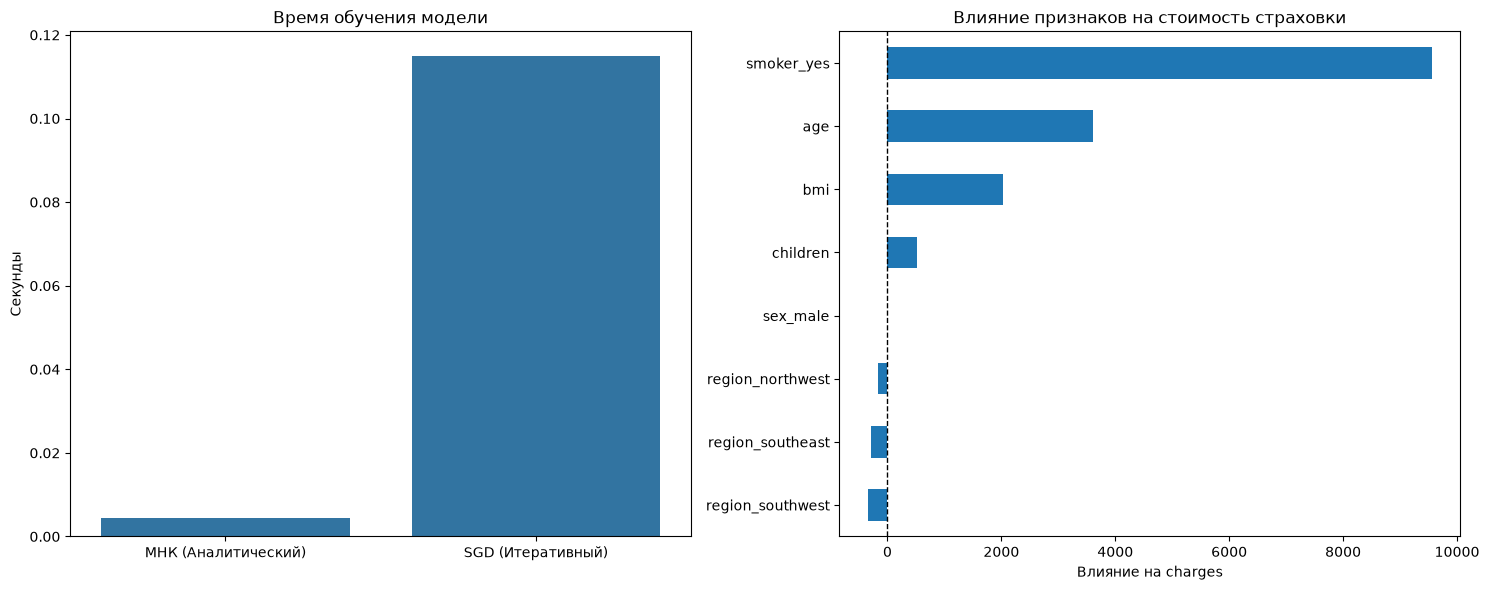

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1 Сравнение времени выполнения
sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

# 2 Веса признаков
weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])
axes[1].set_title("Влияние признаков на стоимость страховки")
axes[1].set_xlabel("Влияние на charges")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

Вывод: наибольший вклад в стоимость страховки вносит курение, следом идёт возраст. Влияние пола и региона минимально, что согласуется с ожидаемой структурой данных.